# Phase 8 — Product Recommendation System (Optional)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import sparse
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

PROC_DIR = Path('../data/processed')
df = pd.read_csv(PROC_DIR / 'olist_with_time_features.csv', parse_dates=['order_purchase_timestamp'])
print('Loaded shape:', df.shape)

Loaded shape: (42724, 48)


## Data preparation: popular-product catalog & train/test split

In [2]:
MIN_PRODUCT_PURCHASES = 20  # lower this if your catalog ends up too small; raise it if matrices are too big

product_counts = df['product_id'].value_counts()
popular_products = product_counts[product_counts >= MIN_PRODUCT_PURCHASES].index
print(f'{len(popular_products):,} products meet the {MIN_PRODUCT_PURCHASES}+ purchase threshold '
      f'(out of {df["product_id"].nunique():,} total)')

interactions = (df[df['product_id'].isin(popular_products)]
                .groupby(['customer_unique_id', 'product_id'])
                .agg(count=('order_id', 'nunique'),
                     first_purchase=('order_purchase_timestamp', 'min'),
                     category=('product_category_name_english', 'first'),
                     avg_price=('price', 'mean'))
                .reset_index())

print(f'{len(interactions):,} customer-product interactions, '
      f'{interactions["customer_unique_id"].nunique():,} customers')

162 products meet the 20+ purchase threshold (out of 17,802 total)
6,118 customer-product interactions, 6,022 customers


In [3]:
# Leave-one-out split: for customers with 2+ distinct popular products,
# hold out their most recently purchased product as the test item.
n_products_per_customer = interactions.groupby('customer_unique_id').size()
eval_customers = n_products_per_customer[n_products_per_customer >= 2].index
print(f'{len(eval_customers):,} customers eligible for evaluation (2+ distinct popular products)')

interactions_sorted = interactions.sort_values(['customer_unique_id', 'first_purchase'])

test_rows = (interactions_sorted[interactions_sorted['customer_unique_id'].isin(eval_customers)]
             .groupby('customer_unique_id').tail(1))
train_rows = interactions_sorted.drop(test_rows.index)

test_relevant = test_rows.groupby('customer_unique_id')['product_id'].apply(set).to_dict()

print(f'Train interactions: {len(train_rows):,}  |  Test (held-out) interactions: {len(test_rows):,}')

95 customers eligible for evaluation (2+ distinct popular products)
Train interactions: 6,023  |  Test (held-out) interactions: 95


In [4]:
# Build the customer x product interaction matrix from TRAIN data only
customers = train_rows['customer_unique_id'].unique()
products = popular_products.tolist()
cust_idx = {c: i for i, c in enumerate(customers)}
prod_idx = {p: i for i, p in enumerate(products)}

rows = train_rows['customer_unique_id'].map(cust_idx)
cols = train_rows['product_id'].map(prod_idx)
vals = train_rows['count'].values

train_matrix = sparse.csr_matrix((vals, (rows, cols)), shape=(len(customers), len(products)))
print('Train interaction matrix shape:', train_matrix.shape,
      f'| density: {train_matrix.nnz / (train_matrix.shape[0]*train_matrix.shape[1]):.4%}')

# What each customer already purchased in TRAIN (to exclude from recommendations)
train_purchased = train_rows.groupby('customer_unique_id')['product_id'].apply(set).to_dict()

Train interaction matrix shape: (6022, 162) | density: 0.6174%


## Evaluation metric functions

In [5]:
def precision_at_k(recommended, relevant, k):
    rec_k = recommended[:k]
    if len(rec_k) == 0:
        return 0.0
    return len(set(rec_k) & relevant) / len(rec_k)

def recall_at_k(recommended, relevant, k):
    if len(relevant) == 0:
        return 0.0
    rec_k = recommended[:k]
    return len(set(rec_k) & relevant) / len(relevant)

def average_precision_at_k(recommended, relevant, k):
    rec_k = recommended[:k]
    hits, score = 0, 0.0
    for i, item in enumerate(rec_k, start=1):
        if item in relevant:
            hits += 1
            score += hits / i
    return score / min(len(relevant), k) if relevant else 0.0

def hit_rate_at_k(recommended, relevant, k):
    return 1.0 if len(set(recommended[:k]) & relevant) > 0 else 0.0

def evaluate_recommender(recommend_fn, eval_customers, test_relevant, k_values=(5, 10)):
    """recommend_fn(customer_id) -> ranked list of product_ids (best first)"""
    rows = []
    for k in k_values:
        precisions, recalls, aps, hits = [], [], [], []
        for cust in eval_customers:
            relevant = test_relevant.get(cust, set())
            if not relevant:
                continue
            recommended = recommend_fn(cust, k)
            precisions.append(precision_at_k(recommended, relevant, k))
            recalls.append(recall_at_k(recommended, relevant, k))
            aps.append(average_precision_at_k(recommended, relevant, k))
            hits.append(hit_rate_at_k(recommended, relevant, k))
        rows.append({
            'k': k,
            'precision@k': np.mean(precisions),
            'recall@k': np.mean(recalls),
            'map@k': np.mean(aps),
            'hit_rate': np.mean(hits),
        })
    return pd.DataFrame(rows)

## Content-Based Recommendation

In [6]:
product_meta = (train_rows.drop_duplicates('product_id')[['product_id', 'category', 'avg_price']]
                .set_index('product_id').reindex(products))
product_meta['avg_price'] = product_meta['avg_price'].fillna(product_meta['avg_price'].median())
product_meta['category'] = product_meta['category'].fillna('unknown')

category_dummies = pd.get_dummies(product_meta['category'], prefix='cat')
price_norm = (product_meta['avg_price'] - product_meta['avg_price'].mean()) / product_meta['avg_price'].std()
content_features = pd.concat([category_dummies, price_norm.rename('price_norm')], axis=1).fillna(0)
content_matrix = content_features.values  # products x features, row order matches `products`

print('Content feature matrix shape:', content_matrix.shape)

Content feature matrix shape: (162, 26)


In [7]:
def get_user_profile_content(customer_id):
    purchased = train_purchased.get(customer_id, set())
    idxs = [prod_idx[p] for p in purchased if p in prod_idx]
    if not idxs:
        return None
    return content_matrix[idxs].mean(axis=0, keepdims=True)

def recommend_content_based(customer_id, k):
    profile = get_user_profile_content(customer_id)
    if profile is None:
        return []
    scores = cosine_similarity(profile, content_matrix)[0]
    purchased = train_purchased.get(customer_id, set())
    ranked = np.argsort(-scores)
    recs = [products[i] for i in ranked if products[i] not in purchased]
    return recs[:k]

# sanity check on one user
sample_customer = next(iter(eval_customers))
print('Sample content-based recs:', recommend_content_based(sample_customer, 5))

Sample content-based recs: ['368c6c730842d78016ad823897a372db', '53759a2ecddad2bb87a079a1f1519f73', 'b0961721fd839e9982420e807758a2a6', '0bcc3eeca39e1064258aa1e932269894', '7e0dc102074f8285580c9777f79c90cf']


## Collaborative Filtering (item-based)

In [8]:
item_user_matrix = train_matrix.T.tocsr()  # products x customers
item_similarity = cosine_similarity(item_user_matrix)  # products x products, dense
print('Item-item similarity matrix shape:', item_similarity.shape)

Item-item similarity matrix shape: (162, 162)


In [9]:
def recommend_collaborative(customer_id, k):
    if customer_id not in cust_idx:
        return []
    c_idx = cust_idx[customer_id]
    user_vector = train_matrix[c_idx].toarray().flatten()  # counts per product
    scores = user_vector @ item_similarity  # weighted sum of similarity to purchased items
    purchased = train_purchased.get(customer_id, set())
    ranked = np.argsort(-scores)
    recs = [products[i] for i in ranked if products[i] not in purchased]
    return recs[:k]

print('Sample CF recs:', recommend_collaborative(sample_customer, 5))

Sample CF recs: ['99a4788cb24856965c36a24e339b6058', 'aca2eb7d00ea1a7b8ebd4e68314663af', '53b36df67ebb7c41585e8d54d6772e08', '368c6c730842d78016ad823897a372db', '53759a2ecddad2bb87a079a1f1519f73']


## Matrix Factorization (bonus, SVD)

In [10]:
N_COMPONENTS = min(50, min(train_matrix.shape) - 1)
svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
customer_factors = svd.fit_transform(train_matrix)   # customers x components
product_factors = svd.components_.T                   # products x components

print(f'SVD with {N_COMPONENTS} components, '
      f'explained variance: {svd.explained_variance_ratio_.sum():.2%}')

SVD with 50 components, explained variance: 53.45%


In [11]:
def recommend_svd(customer_id, k):
    if customer_id not in cust_idx:
        return []
    c_idx = cust_idx[customer_id]
    scores = customer_factors[c_idx] @ product_factors.T
    purchased = train_purchased.get(customer_id, set())
    ranked = np.argsort(-scores)
    recs = [products[i] for i in ranked if products[i] not in purchased]
    return recs[:k]

print('Sample SVD recs:', recommend_svd(sample_customer, 5))

Sample SVD recs: ['fb55982be901439613a95940feefd9ee', '36f60d45225e60c7da4558b070ce4b60', '4fcb3d9a5f4871e8362dfedbdb02b064', '461f43be3bdf8844e65b62d9ac2c7a5a', '29427de7f8a9ee983d9dbc51cec569b4']


## Hybrid Recommendation (bonus)

In [12]:
def minmax(arr):
    lo, hi = arr.min(), arr.max()
    if hi - lo < 1e-9:
        return np.zeros_like(arr)
    return (arr - lo) / (hi - lo)

def recommend_hybrid(customer_id, k, content_weight=0.5):
    if customer_id not in cust_idx:
        return []
    profile = get_user_profile_content(customer_id)
    content_scores = cosine_similarity(profile, content_matrix)[0] if profile is not None \
        else np.zeros(len(products))

    c_idx = cust_idx[customer_id]
    user_vector = train_matrix[c_idx].toarray().flatten()
    cf_scores = user_vector @ item_similarity

    combined = content_weight * minmax(content_scores) + (1 - content_weight) * minmax(cf_scores)
    purchased = train_purchased.get(customer_id, set())
    ranked = np.argsort(-combined)
    recs = [products[i] for i in ranked if products[i] not in purchased]
    return recs[:k]

print('Sample hybrid recs:', recommend_hybrid(sample_customer, 5))

Sample hybrid recs: ['368c6c730842d78016ad823897a372db', '53759a2ecddad2bb87a079a1f1519f73', 'b0961721fd839e9982420e807758a2a6', '0bcc3eeca39e1064258aa1e932269894', '7e0dc102074f8285580c9777f79c90cf']


## Evaluation results

In [13]:
methods = {
    'Content-Based': recommend_content_based,
    'Collaborative Filtering': recommend_collaborative,
    'Matrix Factorization (SVD)': recommend_svd,
    'Hybrid': recommend_hybrid,
}

all_results = []
for name, fn in methods.items():
    res = evaluate_recommender(fn, eval_customers, test_relevant, k_values=(5, 10))
    res.insert(0, 'method', name)
    all_results.append(res)

comparison = pd.concat(all_results, ignore_index=True)
comparison

,method,k,precision@k,recall@k,map@k,hit_rate
0,Content-Based,5,0.109474,0.547368,0.185263,0.547368
1,Content-Based,10,0.078947,0.789474,0.215744,0.789474
2,Collaborative Filtering,5,0.052632,0.263158,0.128596,0.263158
3,Collaborative Filtering,10,0.032632,0.326316,0.139123,0.326316
4,Matrix Factorization (SVD),5,0.004211,0.021053,0.007018,0.021053
5,Matrix Factorization (SVD),10,0.002105,0.021053,0.007018,0.021053
6,Hybrid,5,0.109474,0.547368,0.227368,0.547368
7,Hybrid,10,0.078947,0.789474,0.257849,0.789474


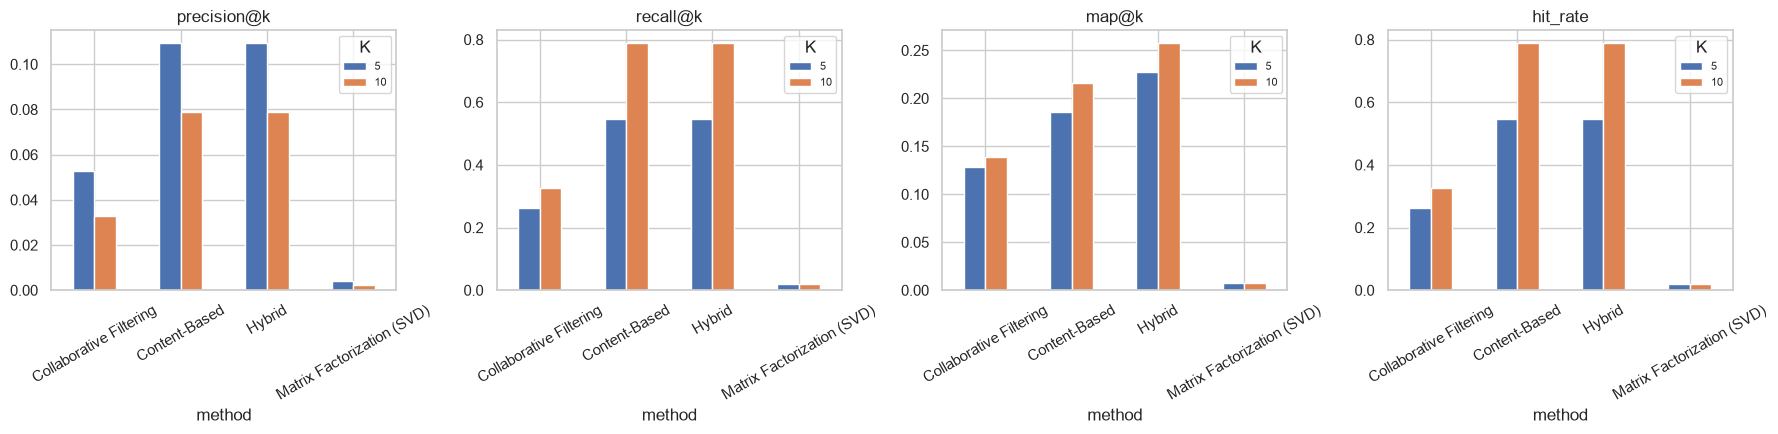

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
metric_cols = ['precision@k', 'recall@k', 'map@k', 'hit_rate']

for ax, metric in zip(axes, metric_cols):
    pivot = comparison.pivot(index='method', columns='k', values=metric)
    pivot.plot(kind='bar', ax=ax, rot=30)
    ax.set_title(metric)
    ax.legend(title='K', fontsize=8)

plt.tight_layout()
plt.show()

## Save recommendation artifacts

In [15]:
import joblib

MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)

recommendation_artifacts = {
    'products': products,
    'prod_idx': prod_idx,
    'customers': customers,
    'cust_idx': cust_idx,
    'content_matrix': content_matrix,
    'content_feature_names': content_features.columns.tolist(),
    'item_similarity': item_similarity,
    'product_meta': product_meta,
    'train_purchased': train_purchased,
}
joblib.dump(recommendation_artifacts, MODELS_DIR / 'recommendation_artifacts.pkl')
print(f"Saved recommendation artifacts to {MODELS_DIR / 'recommendation_artifacts.pkl'}")


Saved recommendation artifacts to ..\models\recommendation_artifacts.pkl
